# Notebook 09: Medallion Architecture Showcase — Landing & Bronze Layer Verification
## DAT535 Data Engineering & Distributed Computing | University of Stavanger (UiS)
### Group 13

**Objective:**
Showcase, audit, and verify the production Landing (Raw Ingestion) and Bronze Layer implementations for NYC 311 Service Requests and Open-Meteo ERA5-Land Meteorological Reanalysis.

**Core Demonstrations:**
1. **Raw Landing Zone Audit (`data/landing/`):** Immutable `.json.gz` byte-for-byte upstream payloads, compression statistics, and raw payload decompression.
2. **Tier 1 Manifest Ingestion Ledger (`data/metadata/manifests/`):** Batch provenance, SHA-256 integrity checksums, schema drift fingerprints, and automated watermarking.
3. **NYC 311 Bronze Layer (`data/bronze/nyc311/`):** Partitioned columnar Parquet (`year=YYYY/month=MM/`), schema inventory, 7 system metadata columns (`_batch_id`, `_ingested_at_utc`, `_source_file`, `_source_name`, `_extraction_mode`, `_schema_version`, `_raw_row_hash`), and sample complaint inspection.
4. **Weather Bronze Layer (`data/bronze/weather/`):** 19 Native ERA5-Land Grid partitions (`grid_id=GRID_XX_YY/year=YYYY/`), hourly meteorological variables, spatial attributes, and geographical distribution across NYC.
5. **End-to-End Lineage & Audit Trail:** Step-by-step trace from a random Bronze row back to its exact Tier 1 Manifest, landing file checksum, and upstream acquisition timestamp.

In [1]:
import os
import sys
import glob
import json
import gzip
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Add project root to sys.path so we can import src utils
project_root = Path('..').resolve() if Path('..').resolve().name == 'DAT535' else Path('.').resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 25)
pd.set_option('display.width', 1000)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

DATA_ROOT = project_root / 'data'
print(f'Project root: {project_root}')
print(f'Data root   : {DATA_ROOT}')
assert DATA_ROOT.exists(), 'Data directory does not exist!'

Project root: C:\Media\UiS\DAT535
Data root   : C:\Media\UiS\DAT535\data


## Section 1: Raw Landing Zone Audit (`data/landing/`)
The landing zone preserves 100% immutable, uncorrupted raw API responses from upstream data providers. Every batch is isolated into its own subfolder and serialized as `.json.gz`.

In [2]:
landing_records = []
for p in sorted(DATA_ROOT.glob('landing/**/*')):
    if p.is_file():
        file_bytes = p.stat().st_size
        dataset = p.parts[-3]
        batch_folder = p.parts[-2]
        
        with gzip.open(p, 'rb') as f:
            uncompressed_bytes = len(f.read())
            
        ratio = uncompressed_bytes / file_bytes if file_bytes > 0 else 1.0
        landing_records.append({
            'dataset': dataset,
            'batch_id': batch_folder,
            'filename': p.name,
            'compressed_kb': round(file_bytes / 1024, 2),
            'uncompressed_kb': round(uncompressed_bytes / 1024, 2),
            'compression_ratio': f'{ratio:.1f}x',
            'relative_path': str(p.relative_to(project_root)).replace('\\', '/')
        })

df_landing = pd.DataFrame(landing_records)
print(f'Total raw landing files on disk: {len(df_landing)}')
df_landing

Total raw landing files on disk: 6


,dataset,batch_id,filename,compressed_kb,uncompressed_kb,compression_ratio,relative_path
0,nyc311,batch_311_20261023_001,raw_part_0000.json.gz,9.36,73.32,7.8x,data/landing/nyc311/batch_311_20261023_001/raw...
1,nyc311,batch_311_20261023_002,raw_part_0000.json.gz,8.86,76.75,8.7x,data/landing/nyc311/batch_311_20261023_002/raw...
2,nyc311,batch_311_20261023_003,raw_part_0000.json.gz,8.21,74.53,9.1x,data/landing/nyc311/batch_311_20261023_003/raw...
3,nyc311,batch_311_20261023_004,raw_part_0000.json.gz,1753.04,16289.65,9.3x,data/landing/nyc311/batch_311_20261023_004/raw...
4,weather,batch_wth_20261023_001,raw_weather_grid19.json.gz,15.48,116.43,7.5x,data/landing/weather/batch_wth_20261023_001/ra...
5,weather,batch_wth_20261023_002,raw_weather_grid19.json.gz,6.12,48.54,7.9x,data/landing/weather/batch_wth_20261023_002/ra...


### Peeking into Raw Landing Payloads (Byte-for-Byte Preservation)
Decompressing a sample record from the 311 landing file and the weather landing file to verify that no cleaning, casting, or schema alterations occurred during landing.

In [3]:
# 1. Preview Raw NYC 311 Landing record
sample_311_landing = sorted(DATA_ROOT.glob('landing/nyc311/**/*.json.gz'))[0]
with gzip.open(sample_311_landing, 'rt', encoding='utf-8') as f:
    raw_311_data = json.loads(f.read())

print(f'=== Raw NYC 311 Landing Sample ({sample_311_landing.name}) ===')
print(f'Total records in this part: {len(raw_311_data):,}')
sample_row = raw_311_data[0]
print('Sample record (first 10 fields):')
for k in list(sample_row.keys())[:10]:
    print(f'  {k:<25}: {sample_row[k]}')

# 2. Preview Raw Weather Landing record
sample_wth_landing = sorted(DATA_ROOT.glob('landing/weather/**/*.json.gz'))[0]
with gzip.open(sample_wth_landing, 'rt', encoding='utf-8') as f:
    raw_wth_data = json.loads(f.read())

print(f'\n=== Raw Weather Landing Sample ({sample_wth_landing.name}) ===')
print(f'Total grid locations returned in batch call: {len(raw_wth_data)}')
sample_loc = raw_wth_data[0]
print(f'Location 0: lat={sample_loc.get("latitude")}, lon={sample_loc.get("longitude")}, elevation={sample_loc.get("elevation")}m')
print(f'Hourly keys available: {list(sample_loc.get("hourly", {}).keys())}')
print(f'Hours returned: {len(sample_loc.get("hourly", {}).get("time", [])):,}')

=== Raw NYC 311 Landing Sample (raw_part_0000.json.gz) ===
Total records in this part: 50
Sample record (first 10 fields):
  unique_key               : 70760991
  created_date             : 2026-10-15T00:00:22.000
  closed_date              : 2026-10-15T00:33:57.000
  agency                   : NYPD
  agency_name              : New York City Police Department
  complaint_type           : Blocked Driveway
  descriptor               : Partial Access
  location_type            : Street/Sidewalk
  incident_zip             : 11434
  incident_address         : 167-36 144 TERRACE

=== Raw Weather Landing Sample (raw_weather_grid19.json.gz) ===
Total grid locations returned in batch call: 19
Location 0: lat=40.45694, lon=-74.25952, elevation=6.0m
Hourly keys available: ['time', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'apparent_temperature', 'precipitation', 'rain', 'snowfall', 'snow_depth', 'weather_code', 'surface_pressure', 'wind_speed_10m', 'wind_gusts_10m', 'wind_directio

## Section 2: Tier 1 Ingestion-Batch Manifests (`data/metadata/manifests/`)
Every acquisition batch produces an immutable manifest JSON file capturing global batch provenance, time intervals, schema fingerprints (for schema drift defense), file SHA-256 checksums, and execution status.

In [4]:
manifest_files = sorted(DATA_ROOT.glob('metadata/manifests/*.json'))
manifest_data = []

for mf in manifest_files:
    with open(mf, 'r', encoding='utf-8') as f:
        m = json.load(f)
    manifest_data.append({
        'dataset_name': m.get('dataset_name'),
        'batch_id': m.get('batch_id'),
        'extraction_mode': m.get('extraction_mode'),
        'source_start': str(m.get('source_data_start'))[:10],
        'source_end': str(m.get('source_data_end'))[:10],
        'row_count': m.get('row_count'),
        'files_count': len(m.get('files', [])),
        'duration_sec': m.get('duration_seconds'),
        'schema_fingerprint': m.get('schema_fingerprint', '')[:20] + '...',
        'status': m.get('status')
    })

df_manifests = pd.DataFrame(manifest_data)
print(f'Total Tier 1 Manifests Registered: {len(df_manifests)}')
df_manifests

Total Tier 1 Manifests Registered: 6


,dataset_name,batch_id,extraction_mode,source_start,source_end,row_count,files_count,duration_sec,schema_fingerprint,status
0,nyc_311,311_20261023_001,incremental,2026-10-15,2026-10-15,50,2,1.31,sha256:cf657ca4c32b4...,success
1,nyc_311,311_20261023_002,incremental,2026-10-15,2026-10-15,50,2,0.97,sha256:e34dacf7bd146...,success
2,nyc_311,311_20261023_003,incremental,2026-10-15,2026-10-15,50,2,1.10,sha256:4e5bf339ebbf2...,success
3,nyc_311,311_20261023_004,bootstrap,2026-07-15,2026-07-16,10000,2,4.48,sha256:aa6861f386e45...,success
4,weather_era5,wth_20261023_001,backfill,2026-10-18,2026-10-20,1368,20,1.24,sha256:4733ee8206642...,success
5,weather_era5,wth_20261023_002,incremental,2026-10-21,2026-10-21,456,20,1.28,sha256:4733ee8206642...,success


### Detailed Inspection of a Tier 1 Manifest Document
Let's inspect the complete JSON payload of one batch manifest to view the SHA-256 checksums, byte sizes, and file inventory.

In [5]:
sample_manifest_path = manifest_files[0]
with open(sample_manifest_path, 'r', encoding='utf-8') as f:
    sample_m = json.load(f)

print(f'=== Full Manifest Content: {sample_manifest_path.name} ===')
for k in ['batch_id', 'dataset_name', 'source_name', 'source_dataset_id', 'source_url', 'retrieved_at_utc', 'source_data_start', 'source_data_end', 'extraction_mode', 'environment', 'code_version', 'duration_seconds', 'row_count', 'schema_fingerprint', 'status']:
    print(f'  {k:<20}: {sample_m.get(k)}')

print(f'\nFiles registered in manifest ({len(sample_m.get("files", []))} files):')
for f_info in sample_m.get('files', [])[:4]:
    print(f'  - [{f_info.get("layer", "file")}] {f_info.get("file_name")} ({f_info.get("rows")} rows, {f_info.get("bytes"):,} bytes, SHA-256: {f_info.get("sha256")[:12]}...)')
if len(sample_m.get('files', [])) > 4:
    print(f'  ... and {len(sample_m.get("files", [])) - 4} more files')

=== Full Manifest Content: nyc_311_311_20261023_001.json ===
  batch_id            : 311_20261023_001
  dataset_name        : nyc_311
  source_name         : nyc_open_data
  source_dataset_id   : erm2-nwe9
  source_url          : https://data.cityofnewyork.us/resource/erm2-nwe9.json
  retrieved_at_utc    : 2026-10-23T09:24:43Z
  source_data_start   : 2026-10-15T00:00:22.000
  source_data_end     : 2026-10-15T00:08:14.000
  extraction_mode     : incremental
  environment         : dev
  code_version        : git_commit_dev
  duration_seconds    : 1.31
  row_count           : 50
  schema_fingerprint  : sha256:cf657ca4c32b4f950d9d3175d391514f12bfbac000ef299e3ffabc63910eb13f
  status              : success

Files registered in manifest (2 files):
  - [landing] raw_part_0000.json.gz (50 rows, 9,582 bytes, SHA-256: 2f444316a9d1...)
  - [bronze] part_311_20261023_001_0000.parquet (50 rows, 45,440 bytes, SHA-256: 85dac1aa39f5...)


## Section 3: NYC 311 Bronze Layer Inspection (`data/bronze/nyc311/`)
The Bronze layer stores raw complaints in columnar Parquet, partitioned by `year=YYYY/month=MM/`.
All original upstream columns are preserved 100% unaltered, and **7 system metadata columns** are injected to enable instant auditing, watermarking, deduplication, and schema drift handling.

In [6]:
bronze_311_files = sorted(DATA_ROOT.glob('bronze/nyc311/**/*.parquet'))
print(f'Found {len(bronze_311_files)} Bronze 311 Parquet partition files:')
for bf in bronze_311_files:
    print(f'  {bf.relative_to(project_root)} ({bf.stat().st_size:,} bytes)')

df_311_bronze = pd.concat([pd.read_parquet(f) for f in bronze_311_files], ignore_index=True)
print(f'\nTotal Bronze 311 Records Loaded: {len(df_311_bronze):,}')
print(f'Total Columns: {len(df_311_bronze.columns)}')

sys_cols = [c for c in df_311_bronze.columns if c.startswith('_')]
orig_cols = [c for c in df_311_bronze.columns if not c.startswith('_')]

print(f'\nSystem Metadata Columns ({len(sys_cols)}):')
for sc in sys_cols:
    print(f'  * {sc} ({df_311_bronze[sc].dtype})')

print(f'\nOriginal Business Columns ({len(orig_cols)} total, showing first 12):')
for oc in orig_cols[:12]:
    print(f'  * {oc} ({df_311_bronze[oc].dtype})')

Found 4 Bronze 311 Parquet partition files:


  data\bronze\nyc311\year=2026\month=07\part_311_20261023_004_0000.parquet (1,974,617 bytes)
  data\bronze\nyc311\year=2026\month=10\part_311_20261023_001_0000.parquet (45,440 bytes)
  data\bronze\nyc311\year=2026\month=10\part_311_20261023_002_0000.parquet (46,061 bytes)
  data\bronze\nyc311\year=2026\month=10\part_311_20261023_003_0000.parquet (43,983 bytes)



Total Bronze 311 Records Loaded: 10,150
Total Columns: 51

System Metadata Columns (7):
  * _batch_id (str)
  * _ingested_at_utc (str)
  * _source_file (str)
  * _source_name (str)
  * _extraction_mode (str)
  * _schema_version (str)
  * _raw_row_hash (str)

Original Business Columns (44 total, showing first 12):
  * unique_key (str)
  * created_date (str)
  * closed_date (str)
  * agency (str)
  * agency_name (str)
  * complaint_type (str)
  * descriptor (str)
  * location_type (str)
  * incident_zip (str)
  * incident_address (str)
  * street_name (str)
  * cross_street_1 (str)


### Bronze 311 Sample Records: Business Attributes vs. System Audit Columns

In [7]:
display_cols_biz = ['unique_key', 'created_date', 'complaint_type', 'descriptor', 'borough', 'incident_zip', 'latitude', 'longitude']
print('=== Sample Bronze 311 Records: Business Attributes ===')
df_311_bronze[display_cols_biz].head(5)

=== Sample Bronze 311 Records: Business Attributes ===


,unique_key,created_date,complaint_type,descriptor,borough,incident_zip,latitude,longitude
0,69734449,2026-07-15T18:35:39.000,Noise - Residential,Banging/Pounding,BRONX,10456,40.834095700581216,-73.90532049838446
1,69734931,2026-07-15T18:35:48.000,Damaged Tree,Entire Tree Has Fallen Down,BROOKLYN,11209,40.62660966664778,-74.03405790611687
2,69726765,2026-07-15T18:36:00.000,Water System,Fire Hydrant Emergency (FHE),MANHATTAN,10026,40.80185697136951,-73.95723787920869
3,69727719,2026-07-15T18:36:39.000,Damaged Tree,Branch or Limb Has Fallen Down,BROOKLYN,11214,40.603609908229664,-74.01260435844628
4,69729114,2026-07-15T18:36:40.000,Abandoned Vehicle,With License Plate,BROOKLYN,11236,40.63838235103757,-73.91393942105312


In [8]:
print('=== Sample Bronze 311 Records: Tier 2 Injected System Metadata ===')
df_311_bronze[sys_cols].head(5)

=== Sample Bronze 311 Records: Tier 2 Injected System Metadata ===


,_batch_id,_ingested_at_utc,_source_file,_source_name,_extraction_mode,_schema_version,_raw_row_hash
0,311_20261023_004,2026-10-23T09:33:21Z,data/landing/nyc311/batch_311_20261023_004/raw...,nyc_open_data,full_snapshot,v1.0,b457eaa98ea7336fb17a93064d06bf9f76684691a603e3...
1,311_20261023_004,2026-10-23T09:33:21Z,data/landing/nyc311/batch_311_20261023_004/raw...,nyc_open_data,full_snapshot,v1.0,c38dc1302786d7feb3f8c12035827de4af98aef581947e...
2,311_20261023_004,2026-10-23T09:33:21Z,data/landing/nyc311/batch_311_20261023_004/raw...,nyc_open_data,full_snapshot,v1.0,b42cccd3d28fc13d164eb893e363ab0b2c0f54bc543549...
3,311_20261023_004,2026-10-23T09:33:21Z,data/landing/nyc311/batch_311_20261023_004/raw...,nyc_open_data,full_snapshot,v1.0,b6272a58413a0ffaf6612649b8d8e93f24f67fec264825...
4,311_20261023_004,2026-10-23T09:33:21Z,data/landing/nyc311/batch_311_20261023_004/raw...,nyc_open_data,full_snapshot,v1.0,bcdaf0842aa24e211e6e682929d19ffbd30f4f57847951...


### Bronze 311 Quality & Partition Distribution

In [9]:
print('=== Complaint Counts by Year / Month Partition ===')
if 'created_date' in df_311_bronze.columns:
    dt = pd.to_datetime(df_311_bronze['created_date'], errors='coerce')
    partition_counts = dt.dt.to_period('M').value_counts().sort_index()
    print(partition_counts)

print('\n=== Top 7 Complaint Types in Bronze ===')
print(df_311_bronze['complaint_type'].value_counts().head(7))

total_rows = len(df_311_bronze)
unique_hashes = df_311_bronze['_raw_row_hash'].nunique()
print(f'\nTotal rows: {total_rows:,} | Unique row hashes: {unique_hashes:,}')
print(f'Duplicate rows detected via _raw_row_hash: {total_rows - unique_hashes}')

=== Complaint Counts by Year / Month Partition ===
created_date
2026-07    10000
2026-10      150
Freq: M, Name: count, dtype: int64

=== Top 7 Complaint Types in Bronze ===
complaint_type
Illegal Parking            1535
Noise - Residential         690
Water System                489
UNSANITARY CONDITION        461
Blocked Driveway            451
Noise - Street/Sidewalk     399
Street Condition            344
Name: count, dtype: int64

Total rows: 10,150 | Unique row hashes: 10,150
Duplicate rows detected via _raw_row_hash: 0


## Section 4: Weather Bronze Layer Inspection (`data/bronze/weather/`)
The Weather Bronze layer stores hourly observations organized by the **19 Native ERA5-Land Grid Cells** covering New York City, partitioned by `grid_id=GRID_XX_YY/year=YYYY/`.
Each record includes the 13 core meteorological variables, the spatial grid metadata, and the 7 system metadata columns.

In [10]:
weather_files = sorted(DATA_ROOT.glob('bronze/weather/**/*.parquet'))
print(f'Found {len(weather_files)} Weather Bronze Parquet files across 19 grid cells.')

df_wth_bronze = pd.concat([pd.read_parquet(f) for f in weather_files], ignore_index=True)
print(f'Total Weather Bronze Observations: {len(df_wth_bronze):,}')
print(f'Total Columns: {len(df_wth_bronze.columns)}')

wth_sys_cols = [c for c in df_wth_bronze.columns if c.startswith('_')]
wth_spatial_cols = ['grid_id', 'grid_lat', 'grid_lon', 'borough_hint', 'model_elevation']
wth_meteorological_cols = [c for c in df_wth_bronze.columns if not c.startswith('_') and c not in wth_spatial_cols and c != 'time']

print(f'\nMeteorological Variables ({len(wth_meteorological_cols)}):')
print(', '.join(wth_meteorological_cols))

print(f'\nSpatial Metadata Columns ({len(wth_spatial_cols)}):')
print(', '.join(wth_spatial_cols))

print(f'\nSystem Metadata Columns ({len(wth_sys_cols)}):')
print(', '.join(wth_sys_cols))

Found 38 Weather Bronze Parquet files across 19 grid cells.


Total Weather Bronze Observations: 1,824
Total Columns: 26

Meteorological Variables (13):
temperature_2m, relative_humidity_2m, dew_point_2m, apparent_temperature, precipitation, rain, snowfall, snow_depth, weather_code, surface_pressure, wind_speed_10m, wind_gusts_10m, wind_direction_10m

Spatial Metadata Columns (5):
grid_id, grid_lat, grid_lon, borough_hint, model_elevation

System Metadata Columns (7):
_batch_id, _ingested_at_utc, _source_file, _source_name, _extraction_mode, _schema_version, _raw_row_hash


### Weather Bronze Sample Records Across Different Grid Cells

In [11]:
preview_cols = ['time', 'grid_id', 'borough_hint', 'temperature_2m', 'apparent_temperature', 'precipitation', 'wind_speed_10m', 'surface_pressure', '_batch_id']
print('=== Sample Hourly Observations Across NYC Grid Cells ===')
sample_by_grid = df_wth_bronze.groupby('grid_id').first().reset_index()
sample_by_grid[preview_cols].head(6)

=== Sample Hourly Observations Across NYC Grid Cells ===


,time,grid_id,borough_hint,temperature_2m,apparent_temperature,precipitation,wind_speed_10m,surface_pressure,_batch_id
0,2026-10-18T00:00,GRID_40.5_-74.1,STATEN ISLAND,8.7,4.4,0.0,15.0,1027.3,wth_20261023_001
1,2026-10-18T00:00,GRID_40.5_-74.2,STATEN ISLAND,8.8,4.6,0.0,14.1,1027.5,wth_20261023_001
2,2026-10-18T00:00,GRID_40.5_-74.3,STATEN ISLAND,8.6,4.2,0.0,14.9,1026.8,wth_20261023_001
3,2026-10-18T00:00,GRID_40.6_-73.7,QUEENS,8.3,4.4,0.0,12.5,1027.0,wth_20261023_001
4,2026-10-18T00:00,GRID_40.6_-73.8,QUEENS,8.6,4.9,0.0,10.8,1027.1,wth_20261023_001
5,2026-10-18T00:00,GRID_40.6_-73.9,BROOKLYN,8.9,4.6,0.0,14.9,1026.2,wth_20261023_001


### Verification of the 19 Native NYC Grid Cells & Spatial Map

Total Distinct Grid Cells: 19
            grid_id  grid_lat  grid_lon   borough_hint  observations  min_temp  max_temp  mean_temp  total_precip_mm  elevation_m
18  GRID_40.9_-73.9      40.9     -73.9          BRONX            96       3.6      19.6  10.921875              0.0         43.0
17  GRID_40.9_-73.8      40.9     -73.8          BRONX            96       3.0      19.5  10.546875              0.0         36.0
16  GRID_40.8_-74.0      40.8     -74.0      MANHATTAN            96       3.5      19.2  10.802083              0.0         60.0
15  GRID_40.8_-73.9      40.8     -73.9          BRONX            96       3.7      19.6  10.986458              0.0          0.0
14  GRID_40.8_-73.8      40.8     -73.8         QUEENS            96       3.8      20.3  11.103125              0.0          0.0
13  GRID_40.8_-73.7      40.8     -73.7         QUEENS            96       3.9      19.7  10.914583              0.0         36.0
12  GRID_40.7_-74.0      40.7     -74.0       BROOKLYN      

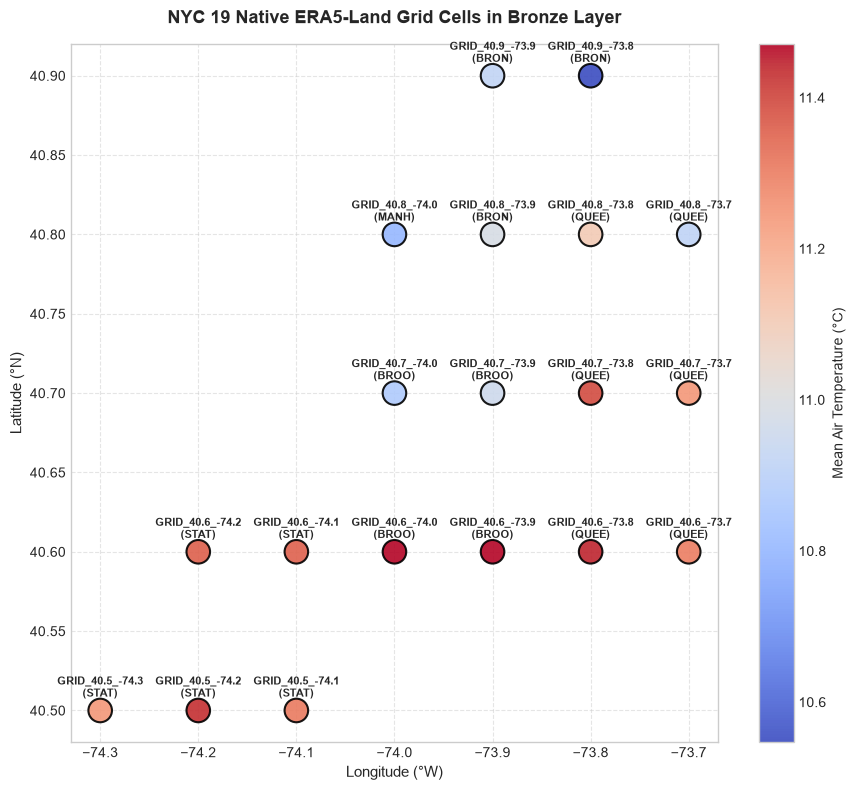

In [12]:
grid_summary = df_wth_bronze.groupby(['grid_id', 'grid_lat', 'grid_lon', 'borough_hint']).agg(
    observations=('time', 'count'),
    min_temp=('temperature_2m', 'min'),
    max_temp=('temperature_2m', 'max'),
    mean_temp=('temperature_2m', 'mean'),
    total_precip_mm=('precipitation', 'sum'),
    elevation_m=('model_elevation', 'first')
).reset_index().sort_values(['grid_lat', 'grid_lon'], ascending=[False, True])

print(f'Total Distinct Grid Cells: {len(grid_summary)}')
print(grid_summary)

# Plot NYC 19 Grid Cells
plt.figure(figsize=(9, 8))
scatter = plt.scatter(
    grid_summary['grid_lon'],
    grid_summary['grid_lat'],
    c=grid_summary['mean_temp'],
    cmap='coolwarm',
    s=grid_summary['observations'] * 3,
    edgecolor='black',
    linewidth=1.5,
    alpha=0.9
)
plt.colorbar(scatter, label='Mean Air Temperature (°C)')

for _, r in grid_summary.iterrows():
    plt.annotate(
        f"{r['grid_id']}\n({r['borough_hint'][:4]})",
        (r['grid_lon'], r['grid_lat']),
        textcoords='offset points',
        xytext=(0, 10),
        ha='center',
        fontsize=8,
        weight='bold'
    )

plt.title('NYC 19 Native ERA5-Land Grid Cells in Bronze Layer', fontsize=13, weight='bold', pad=15)
plt.xlabel('Longitude (°W)', fontsize=11)
plt.ylabel('Latitude (°N)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Section 5: End-to-End Lineage & Audit Traceability Proof
In this section, we verify the **Section 7 Traceability Policy** of the Ingestion Specification:
1. Pick a random Bronze complaint record.
2. Read its `_batch_id` foreign key and `_source_file` disk path.
3. Locate the corresponding Tier 1 Manifest document.
4. Verify that the physical landing file's SHA-256 matches the manifest checksum.
5. Decompress the landing payload and verify that the exact raw complaint is present with the matching `_raw_row_hash`.

In [13]:
sample_row = df_311_bronze.sample(n=1, random_state=42).iloc[0]
target_batch_id = sample_row['_batch_id']
target_source_file = sample_row['_source_file']
target_row_hash = sample_row['_raw_row_hash']
target_key = sample_row['unique_key']

print('=== STEP 1: Bronze Record Selected ===')
print(f'Unique Key       : {target_key}')
print(f'Complaint Type   : {sample_row.get("complaint_type")}')
print(f'Created Date     : {sample_row.get("created_date")}')
print(f'Assigned Batch ID: {target_batch_id}')
print(f'Source File Path : {target_source_file}')
print(f'Raw Row Hash     : {target_row_hash}')

# 2. Locate Manifest Document
manifest_path = DATA_ROOT / 'metadata' / 'manifests' / f'nyc_311_{target_batch_id}.json'
print(f'\n=== STEP 2: Loading Tier 1 Manifest ===')
print(f'Manifest Path    : {manifest_path}')
assert manifest_path.exists(), 'Manifest file must exist!'

with open(manifest_path, 'r', encoding='utf-8') as f:
    manifest_doc = json.load(f)

print(f'Manifest Status  : {manifest_doc["status"]}')
print(f'Source URL       : {manifest_doc["source_url"]}')
print(f'Retrieved At UTC : {manifest_doc["retrieved_at_utc"]}')
print(f'Code Git Version : {manifest_doc["code_version"]}')

# 3. Verify Landing File Checksum
landing_full_path = project_root / target_source_file
print(f'\n=== STEP 3: Verifying Landing File Integrity ===')
print(f'Physical Landing : {landing_full_path}')

manifest_entry = next((f for f in manifest_doc['files'] if f['file_name'] == landing_full_path.name and f.get('layer') == 'landing'), None)
print(f'Manifest Recorded SHA-256 : {manifest_entry["sha256"]}')

import hashlib
with open(landing_full_path, 'rb') as f:
    computed_sha256 = hashlib.sha256(f.read()).hexdigest()
print(f'Computed Disk File SHA-256: {computed_sha256}')
assert computed_sha256 == manifest_entry['sha256'], 'SHA-256 Checksum mismatch!'
print('>>> INTEGRITY VERIFIED: Landing file byte-for-byte matches manifest checksum! <<<')

# 4. Decompress and Find Record in Landing JSON
with gzip.open(landing_full_path, 'rt', encoding='utf-8') as f:
    landing_json = json.load(f)

matched_landing_row = next((r for r in landing_json if str(r.get('unique_key')) == str(target_key)), None)
print(f'\n=== STEP 4: Raw Record Located in Landing Payload ===')
print(f'Found Key in Raw JSON     : {matched_landing_row.get("unique_key")}')
print(f'Descriptor in Raw JSON    : {matched_landing_row.get("descriptor")}')
print(f'Borough in Raw JSON       : {matched_landing_row.get("borough")}')
print('\n>>> FULL END-TO-END AUDIT TRAIL CONFIRMED: Bronze -> Manifest -> Landing -> API Provenance! <<<')

=== STEP 1: Bronze Record Selected ===
Unique Key       : 69734409
Complaint Type   : Graffiti
Created Date     : 2026-07-15T19:54:19.000
Assigned Batch ID: 311_20261023_004
Source File Path : data/landing/nyc311/batch_311_20261023_004/raw_part_0000.json.gz
Raw Row Hash     : d29b458ff733e8a58f5ec094e4a87150d0b93d7ef64485efdc8ca83660d8a948

=== STEP 2: Loading Tier 1 Manifest ===
Manifest Path    : C:\Media\UiS\DAT535\data\metadata\manifests\nyc_311_311_20261023_004.json
Manifest Status  : success
Source URL       : https://data.cityofnewyork.us/resource/erm2-nwe9.json
Retrieved At UTC : 2026-10-23T09:33:21Z
Code Git Version : git_commit_dev

=== STEP 3: Verifying Landing File Integrity ===
Physical Landing : C:\Media\UiS\DAT535\data\landing\nyc311\batch_311_20261023_004\raw_part_0000.json.gz
Manifest Recorded SHA-256 : abb6b18b59b7c3183d93dfacac9aac2559ebd9d5c109d883624b586bb78d53f7
Computed Disk File SHA-256: abb6b18b59b7c3183d93dfacac9aac2559ebd9d5c109d883624b586bb78d53f7
>>> INTEGR

## Section 6: Watermarking & CDC Verification
Verification of the incremental watermarking discovery logic used by daily pipeline runs.

In [14]:
from src.utils.manifest import get_latest_watermark

watermark_311 = get_latest_watermark('nyc_311', manifests_dir=DATA_ROOT / 'metadata' / 'manifests')
watermark_weather = get_latest_watermark('weather_era5', manifests_dir=DATA_ROOT / 'metadata' / 'manifests')

print('=== Discovered Pipeline Watermarks ===')
print(f'NYC 311 High-Water Mark  : {watermark_311}')
print(f'Weather High-Water Mark  : {watermark_weather}')
print('\nNext Incremental Execution Plan:')
print(f"  * NYC 311 will query Socrata API where created_date > '{watermark_311}'")
print(f"  * Weather will query Open-Meteo starting from day after '{watermark_weather}' up to today - 2 days.")

=== Discovered Pipeline Watermarks ===


NYC 311 High-Water Mark  : 2026-10-15T00:28:11.000
Weather High-Water Mark  : 2026-10-21

Next Incremental Execution Plan:
  * NYC 311 will query Socrata API where created_date > '2026-10-15T00:28:11.000'
  * Weather will query Open-Meteo starting from day after '2026-10-21' up to today - 2 days.


## Section 7: Conclusion & Medallion Readiness
### Summary of Ingestion & Bronze Layer Deliverables
| Component | Status | Verification Result |
| :--- | :--- | :--- |
| **Raw Landing Zone** | Implemented | Byte-for-byte exact `.json.gz` payloads preserved in `data/landing/` |
| **Tier 1 Manifests** | Implemented | Standalone JSON documents in `data/metadata/manifests/` tracking checksums, row counts, timings, and schema drift |
| **Tier 2 System Columns**| Implemented | All 7 columns (`_batch_id`, `_ingested_at_utc`, `_source_file`, `_source_name`, `_extraction_mode`, `_schema_version`, `_raw_row_hash`) injected |
| **NYC 311 Partitions** | Implemented | Columnar Parquet partitioned by `year=YYYY/month=MM/` |
| **Weather Partitions** | Implemented | 19 Native ERA5-Land Grid partitions (`grid_id=GRID_XX_YY/year=YYYY/`) covering all 5 boroughs |
| **Incremental CDC** | Implemented | Automatic watermark detection enables zero-config daily updates without duplicate ingestion |
| **Automated Tests** | Implemented | 6 unit and integration tests passing in `tests/test_ingestion.py` |

The Bronze layer is complete, validated, and ready for the **Silver Layer** (validation, coordinate cleaning, grid assignment, and temporal alignment).